# **Imports**

In [ ]:
import os
import gc
import cv2
import time
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import tensorflow as tf

from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    BatchNormalization,
    GlobalAveragePooling2D
)

from tensorflow.keras.applications import MobileNet

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.optimizers.schedules import CosineDecay

from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# **Set Seed**

In [ ]:
import random
import numpy as np
import tensorflow as tf
import os

SEED = 123

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(SEED)

In [ ]:
import os
import shutil

# Source dataset paths
DATASET_PATHS = [
    "/kaggle/input/datasets/waseemalastal/breakhis-breast-cancer-histopathological-dataset/BreakHis - Breast Cancer Histopathological Database/dataset_cancer_v1/dataset_cancer_v1/classificacao_binaria/100X",
    "/kaggle/input/datasets/waseemalastal/breakhis-breast-cancer-histopathological-dataset/BreakHis - Breast Cancer Histopathological Database/dataset_cancer_v1/dataset_cancer_v1/classificacao_binaria/200X",
    "/kaggle/input/datasets/waseemalastal/breakhis-breast-cancer-histopathological-dataset/BreakHis - Breast Cancer Histopathological Database/dataset_cancer_v1/dataset_cancer_v1/classificacao_binaria/400X",
    "/kaggle/input/datasets/waseemalastal/breakhis-breast-cancer-histopathological-dataset/BreakHis - Breast Cancer Histopathological Database/dataset_cancer_v1/dataset_cancer_v1/classificacao_binaria/40X"
]

# Output path
OUTPUT_PATH = "/kaggle/working/train"

classes = ["benign", "malignant"]

os.makedirs(OUTPUT_PATH, exist_ok=True)

for cls in classes:
    dst_folder = os.path.join(OUTPUT_PATH, cls.replace(" ", "_"))
    os.makedirs(dst_folder, exist_ok=True)

    total_count = 0

    # Loop through all dataset splits
    for dataset_path in DATASET_PATHS:
        src_folder = os.path.join(dataset_path, cls)

        if not os.path.exists(src_folder):
            continue

        images = [
            f for f in os.listdir(src_folder)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]

        for img in images:
            src_path = os.path.join(src_folder, img)

            # Avoid overwriting same filename
            new_name = f"{os.path.basename(dataset_path)}_{img}"
            dst_path = os.path.join(dst_folder, new_name)

            shutil.copy2(src_path, dst_path)

        total_count += len(images)

    print(f"Class {cls}: {total_count} images copied.")

print("All train + test + validation images merged into one train folder.")

Class benign: 2480 images copied.
Class malignant: 5429 images copied.
All train + test + validation images merged into one train folder.


In [ ]:
train_dir = "/kaggle/working/train"

# **Data Visualization**

Classes: ['malignant', 'benign']


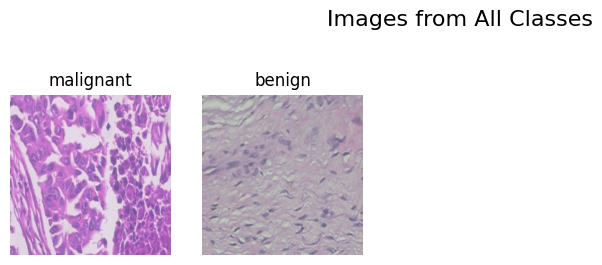

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os
import random

classes = os.listdir(train_dir)
print("Classes:", classes)

# Show one random image from each class
plt.figure(figsize=(12, 6))
for i, cls in enumerate(classes):
    cls_path = os.path.join(train_dir, cls)

    # Pick a random image from that class
    img_name = random.choice(os.listdir(cls_path))
    img_path = os.path.join(cls_path, img_name)

    # Read image
    img = mpimg.imread(img_path)

    # Plot
    plt.subplot(2, 5, i+1)  # 2 rows, 5 columns
    plt.imshow(img)
    plt.title(cls)
    plt.axis("off")

plt.suptitle("Images from All Classes", fontsize=16)
plt.show()

/tmp/ipykernel_58/3288521508.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="label", y="count", data=df, palette=he_colors)


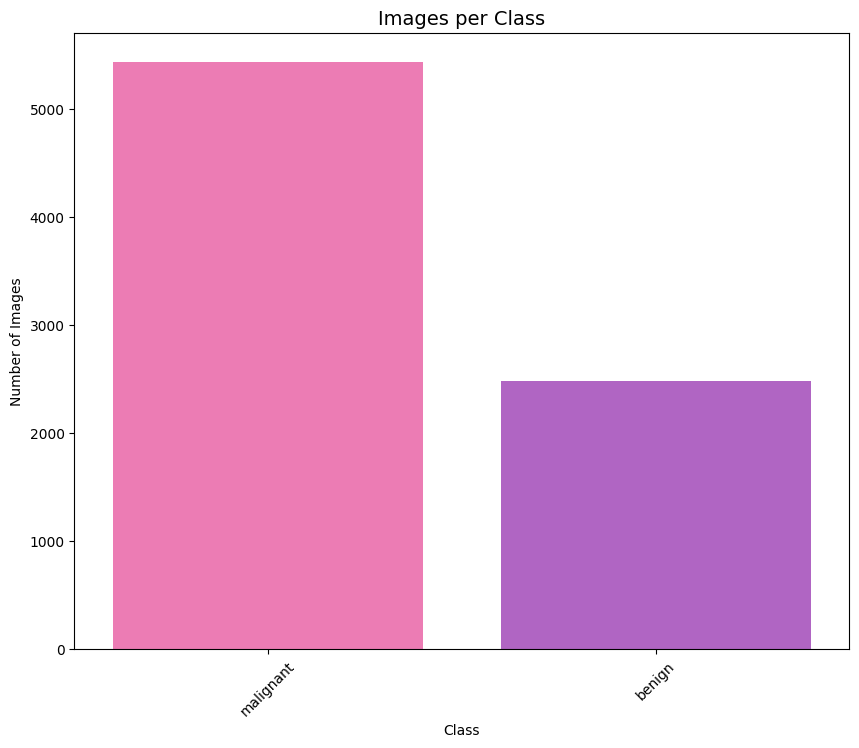

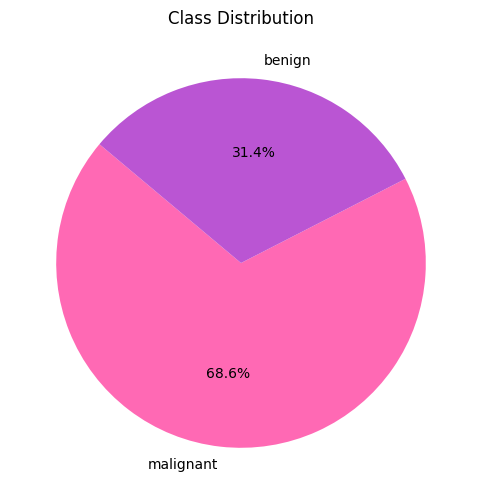

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Count images per class
df = pd.DataFrame([(cls, len(os.listdir(os.path.join(train_dir, cls))))
                   for cls in os.listdir(train_dir)], columns=["label", "count"])

# H&E-inspired colors (purple/blue + pink)
he_colors = ["#FF69B4", "#BA55D3"]

# Bar chart
plt.figure(figsize=(10, 8))
sns.barplot(x="label", y="count", data=df, palette=he_colors)
plt.xticks(rotation=45)
plt.title("Images per Class", fontsize=14)
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

# Pie chart
df.set_index("label")["count"].plot(kind="pie", autopct="%1.1f%%",
                                    startangle=140, figsize=(6,6),
                                    colors=he_colors)
plt.title("Class Distribution")
plt.ylabel("")
plt.show()

# **Label Encoding**

In [ ]:
import os
import re
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# ============================================================
# Build DataFrame
# ============================================================

image_paths, class_names = [], []

for cls in sorted(os.listdir(train_dir)):
    cls_path = os.path.join(train_dir, cls)

    if not os.path.isdir(cls_path):
        continue

    for img in os.listdir(cls_path):
        image_paths.append(os.path.join(cls_path, img))
        class_names.append(cls)

df_all = pd.DataFrame({
    'image_path': image_paths,
    'label': class_names
})


# ============================================================
# Extract BreakHis patient ID
# ============================================================

def extract_patient_id(path):
    filename = os.path.basename(path)

    # Remove magnification prefix
    # Example:
    # 400X_SOB_B_F-14-21998EF-40-001.png

    filename = re.sub(r'^\d+X_', '', filename)

    # Now filename starts with:
    # SOB_B_F-14-21998EF-40-001.png
    # SOB_M_DC-01-1234-40-001.png

    parts = filename.split('-')

    if len(parts) >= 3:
        # Patient ID consists of:
        # F-14-21998EF
        #
        # or:
        # DC-01-1234

        return '-'.join(parts[0].split('_')[-1:] + parts[1:3])

    return None


df_all['patient_id'] = df_all['image_path'].apply(extract_patient_id)


# ============================================================
# Label encoding
# ============================================================

le = LabelEncoder()
df_all['label_num'] = le.fit_transform(df_all['label'])

CLASS_NAMES = list(le.classes_)


# ============================================================
# Verification
# ============================================================

print(f"Total images: {len(df_all)}")
print(f"Classes: {CLASS_NAMES}")

print("\nMissing patient IDs:",
      df_all['patient_id'].isna().sum())

print("\nUnique patients:",
      df_all['patient_id'].nunique())

print("\nPatients per class:")
print(
    df_all.groupby('label')['patient_id']
    .nunique()
)

print("\nExample patient IDs:")
print(df_all[['image_path', 'patient_id', 'label']].head(20))

Total images: 7909
Classes: ['benign', 'malignant']

Missing patient IDs: 0

Unique patients: 82

Patients per class:
label
benign       24
malignant    58
Name: patient_id, dtype: int64

Example patient IDs:
                                           image_path     patient_id   label
0   /kaggle/working/train/benign/200X_SOB_B_F-14-9...      F-14-9133  benign
1   /kaggle/working/train/benign/200X_SOB_B_PT-14-...    PT-14-22704  benign
2   /kaggle/working/train/benign/100X_SOB_B_F-14-2...   F-14-21998CD  benign
3   /kaggle/working/train/benign/200X_SOB_B_F-14-9...      F-14-9133  benign
4   /kaggle/working/train/benign/100X_SOB_B_TA-14-...  TA-14-21978AB  benign
5   /kaggle/working/train/benign/40X_SOB_B_A-14-22...   A-14-22549AB  benign
6   /kaggle/working/train/benign/100X_SOB_B_TA-14-...    TA-14-3411F  benign
7   /kaggle/working/train/benign/40X_SOB_B_F-14-14...     F-14-14134  benign
8   /kaggle/working/train/benign/100X_SOB_B_PT-14-...    PT-14-22704  benign
9   /kaggle/working/t

# **Train-Test-Split**

In [ ]:
import os
import numpy as np
import pandas as pd


SEED = 123
TARGET = 500


# ============================================================
# 1. ONE ROW PER PATIENT
# ============================================================

patient_df = (
    df_all[['patient_id', 'label']]
    .drop_duplicates()
    .sort_values(['label', 'patient_id'])
    .reset_index(drop=True)
)

print("=" * 60)
print("PATIENT INFORMATION")
print("=" * 60)

print(f"\nTotal patients: {len(patient_df)}")

print("\nPatients per class:")
print(patient_df['label'].value_counts())


# ============================================================
# 2. COUNT IMAGES PER PATIENT
# ============================================================

patient_counts = (
    df_all
    .groupby(['patient_id', 'label'])
    .size()
    .reset_index(name='image_count')
)

print("\nImages per patient:")
print(patient_counts.head())


# ============================================================
# 3. EXACT DISJOINT SUBSET SEARCH
# ============================================================

def find_two_exact_groups(patient_counts, target=500):
    """
    Find TWO DISJOINT groups of patients such that:

        Group 1 = exactly target images
        Group 2 = exactly target images

    Patients are never split.

    Returns:
        group1_ids, group2_ids

    Raises:
        ValueError if exact solution does not exist.
    """

    patients = patient_counts[['patient_id', 'image_count']].reset_index(drop=True)
    n = len(patients)

    # --------------------------------------------------------
    # State:
    # (validation_total, test_total)
    #
    # For every patient we can:
    #   0 -> leave in training
    #   1 -> validation
    #   2 -> test
    #
    # We only keep totals <= target.
    # --------------------------------------------------------

    states = {(0, 0): None}

    # To reconstruct the solution
    parents = []

    for i in range(n):

        patient_id = patients.loc[i, 'patient_id']
        count = int(patients.loc[i, 'image_count'])

        new_states = dict(states)
        parent_info = {}

        for state in states:

            val_total, test_total = state

            # ------------------------------------------------
            # Put patient into VALIDATION
            # ------------------------------------------------
            new_val = val_total + count

            if new_val <= target:
                new_state = (new_val, test_total)

                if new_state not in new_states:
                    new_states[new_state] = state
                    parent_info[new_state] = (state, 1)

            # ------------------------------------------------
            # Put patient into TEST
            # ------------------------------------------------
            new_test = test_total + count

            if new_test <= target:
                new_state = (val_total, new_test)

                if new_state not in new_states:
                    new_states[new_state] = state
                    parent_info[new_state] = (state, 2)

        states = new_states
        parents.append(parent_info)

        # ----------------------------------------------------
        # Exact solution found
        # ----------------------------------------------------
        if (target, target) in states:
            break

    # ========================================================
    # CHECK WHETHER EXACT SOLUTION EXISTS
    # ========================================================

    if (target, target) not in states:
        raise ValueError(
            f"\nNo exact patient-level solution exists "
            f"for {target} images per class."
        )

    # ========================================================
    # RECONSTRUCT SELECTED PATIENTS
    # ========================================================

    val_ids = []
    test_ids = []

    current_state = (target, target)

    for i in range(len(parents) - 1, -1, -1):

        parent_info = parents[i]

        if current_state in parent_info:

            previous_state, assignment = parent_info[current_state]
            patient_id = patients.loc[i, 'patient_id']

            if assignment == 1:
                val_ids.append(patient_id)
            elif assignment == 2:
                test_ids.append(patient_id)

            current_state = previous_state

    val_ids.reverse()
    test_ids.reverse()

    return val_ids, test_ids


# ============================================================
# 4. FIND EXACT 500+500 FOR EACH CLASS
# ============================================================

all_val_ids = []
all_test_ids = []

for label in sorted(patient_counts['label'].unique()):

    print("\n" + "=" * 60)
    print(f"SEARCHING EXACT SPLIT FOR: {label.upper()}")
    print("=" * 60)

    class_patients = patient_counts[patient_counts['label'] == label].copy()

    val_ids, test_ids = find_two_exact_groups(class_patients, target=TARGET)

    all_val_ids.extend(val_ids)
    all_test_ids.extend(test_ids)

    print(f"\nValidation {label}: {len(val_ids)} patients")
    print(f"Test {label}: {len(test_ids)} patients")


# ============================================================
# 5. CREATE PATIENT SPLITS
# ============================================================

val_patients = patient_df[patient_df['patient_id'].isin(all_val_ids)].copy()
test_patients = patient_df[patient_df['patient_id'].isin(all_test_ids)].copy()
train_patients = patient_df[
    ~patient_df['patient_id'].isin(all_val_ids + all_test_ids)
].copy()


# ============================================================
# 6. ASSIGN ALL IMAGES BY PATIENT
# ============================================================

train_df = df_all[df_all['patient_id'].isin(train_patients['patient_id'])].copy()
val_df = df_all[df_all['patient_id'].isin(val_patients['patient_id'])].copy()
test_df = df_all[df_all['patient_id'].isin(test_patients['patient_id'])].copy()


# ============================================================
# 7. SPLIT SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("FINAL PATIENT-LEVEL SPLIT")
print("=" * 60)

print("\nTrain:")
print(f"  Images   : {len(train_df)}")
print(f"  Patients : {train_df['patient_id'].nunique()}")

print("\nValidation:")
print(f"  Images   : {len(val_df)}")
print(f"  Patients : {val_df['patient_id'].nunique()}")

print("\nTest:")
print(f"  Images   : {len(test_df)}")
print(f"  Patients : {test_df['patient_id'].nunique()}")


# ============================================================
# 8. CLASS DISTRIBUTION
# ============================================================

print("\n" + "=" * 60)
print("CLASS DISTRIBUTION")
print("=" * 60)

print("\nTrain:")
print(train_df['label'].value_counts())

print("\nValidation:")
print(val_df['label'].value_counts())

print("\nTest:")
print(test_df['label'].value_counts())


# ============================================================
# 9. PATIENT DISTRIBUTION
# ============================================================

print("\n" + "=" * 60)
print("PATIENT DISTRIBUTION BY CLASS")
print("=" * 60)

print("\nTrain:")
print(train_patients['label'].value_counts())

print("\nValidation:")
print(val_patients['label'].value_counts())

print("\nTest:")
print(test_patients['label'].value_counts())


# ============================================================
# 10. EXACT TARGET ASSERTIONS
# ============================================================

print("\n" + "=" * 60)
print("EXACT 500-IMAGE CHECK")
print("=" * 60)

val_counts = val_df['label'].value_counts().to_dict()
test_counts = test_df['label'].value_counts().to_dict()

assert val_counts.get('benign', 0) == 500
assert val_counts.get('malignant', 0) == 500

assert test_counts.get('benign', 0) == 500
assert test_counts.get('malignant', 0) == 500

print("\n✓ Validation = exactly 500 benign + 500 malignant")
print("✓ Test       = exactly 500 benign + 500 malignant")
print("✓ Neither split exceeds 500 images per class.")


# ============================================================
# 11. PATIENT LEAKAGE CHECK
# ============================================================

train_ids = set(train_patients['patient_id'])
val_ids = set(val_patients['patient_id'])
test_ids = set(test_patients['patient_id'])

assert len(train_ids & val_ids) == 0
assert len(train_ids & test_ids) == 0
assert len(val_ids & test_ids) == 0

print("\n✓ No patient overlap between splits.")


# ============================================================
# 12. IMAGE ASSIGNMENT CHECK
# ============================================================

total_split_images = len(train_df) + len(val_df) + len(test_df)

assert total_split_images == len(df_all)

print("✓ All images assigned exactly once.")
print(f"\nTotal images: {total_split_images}")

PATIENT INFORMATION

Total patients: 82

Patients per class:
label
malignant    58
benign       24
Name: count, dtype: int64

Images per patient:
     patient_id      label  image_count
0  A-14-22549AB     benign          121
1  A-14-22549CD     benign          132
2   A-14-22549G     benign          130
3  A-14-29960CD     benign           61
4   DC-14-10926  malignant           39

SEARCHING EXACT SPLIT FOR: BENIGN

Validation benign: 4 patients
Test benign: 5 patients

SEARCHING EXACT SPLIT FOR: MALIGNANT

Validation malignant: 5 patients
Test malignant: 5 patients

FINAL PATIENT-LEVEL SPLIT

Train:
  Images   : 5909
  Patients : 63

Validation:
  Images   : 1000
  Patients : 9

Test:
  Images   : 1000
  Patients : 10

CLASS DISTRIBUTION

Train:
label
malignant    4429
benign       1480
Name: count, dtype: int64

Validation:
label
benign       500
malignant    500
Name: count, dtype: int64

Test:
label
benign       500
malignant    500
Name: count, dtype: int64

PATIENT DISTRIBUTION

In [ ]:
print(train_df['label_num'].value_counts())

label_num
1    4429
0    1480
Name: count, dtype: int64


# **Create folders for training augmentation**

In [ ]:
train_dir_aug = "train_aug"  # folder for augmented training images
os.makedirs(train_dir_aug, exist_ok=True)

for cls in train_df["label"].unique():
    os.makedirs(os.path.join(train_dir_aug, cls), exist_ok=True)

# **Augmentation (Oversampling)**

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from PIL import Image
import numpy as np
import os

datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.05,
    height_shift_range=0.05,
    shear_range=0.05,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

target_count = 4400  # desired max images per class

for cls in train_df["label"].unique():
    cls_train_images = train_df[train_df['label'] == cls]["image_path"].tolist()
    cls_aug_path = os.path.join(train_dir_aug, cls)

    # Copy original images to augmented folder
    for img_path in cls_train_images:
        img_name = os.path.basename(img_path)
        dest_path = os.path.join(cls_aug_path, img_name)
        if not os.path.exists(dest_path):
            Image.open(img_path).convert("RGB").save(dest_path)

    # Now calculate current count AFTER copying originals
    current_count = len(os.listdir(cls_aug_path))

    needed = target_count - current_count
    if needed <= 0:
        print(f"Skipping {cls}: {current_count} images already present.")
        continue

    print(f"Augmenting {cls}: generating {needed} images...")

    img_index = 0
    cls_aug_images = [os.path.join(cls_aug_path, f) for f in os.listdir(cls_aug_path)]
    for _ in range(needed):
        img_path = cls_aug_images[img_index % len(cls_train_images)]
        img = np.expand_dims(np.array(Image.open(img_path).convert("RGB")), axis=0)
        aug_iter = datagen.flow(img, batch_size=1,
                                save_to_dir=cls_aug_path,
                                save_prefix="aug",
                                save_format="jpg")
        next(aug_iter)
        img_index += 1

# After all classes, print final counts
print("\n✅ Data augmentation completed.\n")
for cls in os.listdir(train_dir_aug):
    count = len(os.listdir(os.path.join(train_dir_aug, cls)))
    print(f"{cls}: {count} images")

Augmenting benign: generating 5 images...
Skipping malignant: 4429 images already present.

✅ Data augmentation completed.

malignant: 4429 images
benign: 4400 images


# **Recreate train_df from augmented folder**

In [ ]:
train_image_paths = []
train_labels_num = []

for cls in os.listdir(train_dir_aug):
    cls_path = os.path.join(train_dir_aug, cls)
    for img_name in os.listdir(cls_path):
        train_image_paths.append(os.path.join(cls_path, img_name))
        train_labels_num.append(le.transform([cls])[0])

train_df_aug = pd.DataFrame({
    "image_path": train_image_paths,
    "label_num": train_labels_num
})

print("Class distribution after augmentation:")
print(train_df_aug["label_num"].value_counts())

Class distribution after augmentation:
label_num
1    4429
0    4400
Name: count, dtype: int64


# **Data-Augmentation**

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet import preprocess_input

batch_size = 32
img_size = (224, 224)

# Training augmentation
tr_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=30,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    brightness_range=[0.8, 1.2],
    shear_range=10,
    fill_mode='nearest'
)

# Test/validation generator (no augmentation)
ts_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

# Convert 'label_num' columns to string type for flow_from_dataframe with class_mode='sparse'
train_df_aug['label_num'] = train_df_aug['label_num'].astype(str)
val_df['label_num'] = val_df['label_num'].astype(str)
test_df['label_num'] = test_df['label_num'].astype(str)

train_gen = tr_gen.flow_from_dataframe(train_df_aug, x_col='image_path', y_col='label_num',
                                       target_size=img_size, class_mode='sparse',
                                       color_mode='rgb', shuffle=True, batch_size=batch_size,seed=SEED)

valid_gen = ts_gen.flow_from_dataframe(val_df, x_col='image_path', y_col='label_num',
                                       target_size=img_size, class_mode='sparse',
                                       color_mode='rgb', shuffle=True, batch_size=batch_size,seed=SEED)

test_gen = ts_gen.flow_from_dataframe(test_df, x_col='image_path', y_col='label_num',
                                      target_size=img_size, class_mode='sparse',
                                      color_mode='rgb', shuffle=False, batch_size=batch_size,seed=SEED)

Found 8829 validated image filenames belonging to 2 classes.
Found 1000 validated image filenames belonging to 2 classes.
Found 1000 validated image filenames belonging to 2 classes.


# **Removing Unreadble File**

In [ ]:
from PIL import Image
import os

bad_files = []

for filepath in train_gen.filepaths:
    try:
        with Image.open(filepath) as img:
            img.verify()
    except Exception as e:
        bad_files.append((filepath, str(e)))

print(f"Total files: {len(train_gen.filepaths)}")
print(f"Bad files: {len(bad_files)}")

for filepath, error in bad_files:
    print(filepath)
    print(" ->", error)

Total files: 8829
Bad files: 0


In [ ]:
from PIL import Image
import os

bad_files = []

for filepath in train_gen.filepaths:
    try:
        with Image.open(filepath) as img:
            img.verify()
    except Exception:
        bad_files.append(filepath)

print(f"Found {len(bad_files)} corrupted/unreadable images.")

for filepath in bad_files:
    print("Removing:", filepath)
    os.remove(filepath)

Found 0 corrupted/unreadable images.


# **MobileNet**

In [ ]:
# ============================================================
# SELF-DISTILLATION STUDENT
# Architecturally identical to baseline
# ============================================================

NUM_CLASSES = 2


def create_model(input_shape=(224, 224, 3), num_classes=2):

    inputs = Input(shape=input_shape)

    # --------------------------------------------------------
    # Pretrained MobileNet
    # --------------------------------------------------------
    base = MobileNet(weights="imagenet", include_top=False, input_tensor=inputs)

    # --------------------------------------------------------
    # Freeze most layers
    # --------------------------------------------------------
    for layer in base.layers[:-30]:
        layer.trainable = False

    for layer in base.layers[-30:]:
        layer.trainable = True

    # --------------------------------------------------------
    # Classification head
    # EXACTLY SAME AS BASELINE
    # --------------------------------------------------------
    x = base.output
    x = GlobalAveragePooling2D()(x)
    x = Dense(512, activation="relu")(x)
    x = BatchNormalization()(x)
    x = Dropout(0.5)(x)
    x = Dense(256, activation="relu")(x)
    x = Dropout(0.4)(x)

    # --------------------------------------------------------
    # Output
    # Keep logits for KD loss
    # Do NOT use softmax here
    # --------------------------------------------------------
    outputs = Dense(num_classes, activation=None, name="logits")(x)

    return Model(inputs, outputs, name="MobileNet_SD")


# ============================================================
# CREATE STUDENT
# ============================================================

student = create_model(input_shape=(224, 224, 3), num_classes=NUM_CLASSES)

student.summary()

/tmp/ipykernel_58/1182117882.py:16: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = MobileNet(weights="imagenet", include_top=False, input_tensor=inputs)
I0000 00:00:1790355416.642464      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790355416.645245      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNet_SD"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_bn (BatchNormalization)   │ (None, 112, 112, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_relu (ReLU)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1 (DepthwiseConv2D)     │ (None, 112, 112, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_bn                    │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_relu (ReLU)           │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1 (Conv2D)              │ (None, 112, 112, 64)   │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_bn                    │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_relu (ReLU)           │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pad_2 (ZeroPadding2D)      │ (None, 113, 113, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2 (DepthwiseConv2D)     │ (None, 56, 56, 64)     │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_bn                    │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_relu (ReLU)           │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2 (Conv2D)              │ (None, 56, 56, 128)    │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_relu (ReLU)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3 (DepthwiseConv2D)     │ (None, 56, 56, 128)    │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_relu (ReLU)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3 (Conv2D)              │ (None, 56, 56, 128)    │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 3,887,554 (14.83 MB)

 Trainable params: 3,053,314 (11.65 MB)

 Non-trainable params: 834,240 (3.18 MB)

Notice that I use logits rather than softmax. This is important because knowledge distillation works more cleanly with temperature-scaled logits.

# **EMA Teacher**

In [ ]:
# ============================================================
# CREATE EMA TEACHER
# ============================================================

teacher = create_model()

teacher.set_weights(
    student.get_weights()
)

teacher.trainable = False

print("Student:", student.name)
print("Teacher:", teacher.name)

/tmp/ipykernel_58/1182117882.py:16: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = MobileNet(weights="imagenet", include_top=False, input_tensor=inputs)


Student: MobileNet_SD
Teacher: MobileNet_SD


# **Self-distillation loss**

In [ ]:
temperature = 7.0
alpha = 0.3


def distillation_loss(student_logits, teacher_logits, labels, temperature=7.0, alpha=0.3):

    # --------------------------------------------------------
    # Hard-label loss
    # --------------------------------------------------------
    ce_loss = tf.reduce_mean(
        tf.keras.losses.sparse_categorical_crossentropy(
            labels, student_logits, from_logits=True
        )
    )

    # --------------------------------------------------------
    # Teacher soft targets
    # --------------------------------------------------------
    teacher_log_probs = tf.nn.log_softmax(teacher_logits / temperature, axis=1)
    teacher_probs = tf.exp(teacher_log_probs)

    # --------------------------------------------------------
    # Student soft targets
    # --------------------------------------------------------
    student_log_probs = tf.nn.log_softmax(student_logits / temperature, axis=1)

    # --------------------------------------------------------
    # KL divergence
    # --------------------------------------------------------
    kd_loss = tf.reduce_mean(
        tf.reduce_sum(
            teacher_probs * (teacher_log_probs - student_log_probs),
            axis=1
        )
    )

    # --------------------------------------------------------
    # Temperature scaling
    # --------------------------------------------------------
    kd_loss *= temperature ** 2

    # --------------------------------------------------------
    # Combined loss
    # --------------------------------------------------------
    total_loss = (1.0 - alpha) * ce_loss + alpha * kd_loss

    return total_loss, ce_loss, kd_loss

# **EMA Update**

In [ ]:
# ============================================================
# EMA TEACHER UPDATE
# ============================================================

EMA_DECAY = 0.995


def update_teacher(student, teacher):

    for student_var, teacher_var in zip(
        student.weights,
        teacher.weights
    ):

        teacher_var.assign(
            EMA_DECAY * teacher_var
            +
            (1.0 - EMA_DECAY) * student_var
        )

# **Optimizer**

In [ ]:
# ============================================================
# OPTIMIZER
# ============================================================

steps_per_epoch = len(train_gen)

EPOCHS = 30

lr_schedule = CosineDecay(
    initial_learning_rate=3e-4,
    decay_steps=steps_per_epoch * EPOCHS,
    alpha=1e-6
)
optimizer = Adam(
    learning_rate=lr_schedule
)

# **Training metrics**

In [ ]:
# ============================================================
# METRICS
# ============================================================

train_loss_metric = tf.keras.metrics.Mean(
    name="train_loss"
)

train_acc_metric = tf.keras.metrics.SparseCategoricalAccuracy(
    name="train_accuracy"
)

val_loss_metric = tf.keras.metrics.Mean(
    name="val_loss"
)

val_acc_metric = tf.keras.metrics.SparseCategoricalAccuracy(
    name="val_accuracy"
)

# **Custom self-distillation training step**

In [ ]:
# ============================================================
# TRAINING STEP
# ============================================================

@tf.function
def train_step(images, labels):

    with tf.GradientTape() as tape:
        student_logits = student(images, training=True)
        teacher_logits = teacher(images, training=False)

        total_loss, ce_loss, kd_loss = distillation_loss(
            student_logits, teacher_logits, labels, temperature, alpha
        )

    gradients = tape.gradient(total_loss, student.trainable_variables)
    optimizer.apply_gradients(zip(gradients, student.trainable_variables))

    update_teacher(student, teacher)

    train_loss_metric.update_state(total_loss)
    train_acc_metric.update_state(labels, student_logits)

    return total_loss, ce_loss, kd_loss

# **Validation step**

In [ ]:
# ============================================================
# VALIDATION STEP
# ============================================================

@tf.function
def validation_step(images, labels):

    logits = student(images, training=False)

    loss = tf.reduce_mean(
        tf.keras.losses.sparse_categorical_crossentropy(labels, logits, from_logits=True)
    )

    val_loss_metric.update_state(loss)
    val_acc_metric.update_state(labels, logits)

# **Training loop**

In [ ]:
# ============================================================
# SELF-DISTILLATION TRAINING WITH PROGRESS BAR
# ============================================================

from tqdm.auto import tqdm

best_val_acc = 0.0
patience = 8
wait = 0

history = {
    "loss": [],
    "accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "ce_loss": [],
    "kd_loss": []
}

best_student_weights = None
best_teacher_weights = None


for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    # --------------------------------------------------------
    # Reset metrics
    # --------------------------------------------------------
    train_loss_metric.reset_state()
    train_acc_metric.reset_state()

    val_loss_metric.reset_state()
    val_acc_metric.reset_state()

    epoch_ce = []
    epoch_kd = []

    # ========================================================
    # TRAIN
    # ========================================================

    train_gen.reset()

    train_bar = tqdm(range(len(train_gen)), desc="Training", unit="batch", leave=True)

    for step in train_bar:

        images, labels = next(train_gen)

        total_loss, ce_loss, kd_loss = train_step(images, labels)

        epoch_ce.append(float(ce_loss))
        epoch_kd.append(float(kd_loss))

        # Update progress bar
        train_bar.set_postfix(
            loss=f"{float(total_loss):.4f}",
            acc=f"{float(train_acc_metric.result()):.4f}",
            ce=f"{float(ce_loss):.4f}",
            kd=f"{float(kd_loss):.4f}"
        )

    # ========================================================
    # VALIDATION
    # ========================================================

    valid_gen.reset()

    val_bar = tqdm(range(len(valid_gen)), desc="Validation", unit="batch", leave=True)

    for step in val_bar:

        images, labels = next(valid_gen)

        validation_step(images, labels)

        # Update validation progress bar
        val_bar.set_postfix(
            loss=f"{float(val_loss_metric.result()):.4f}",
            acc=f"{float(val_acc_metric.result()):.4f}"
        )

    # ========================================================
    # EPOCH RESULTS
    # ========================================================

    train_loss = float(train_loss_metric.result())
    train_acc = float(train_acc_metric.result())

    val_loss = float(val_loss_metric.result())
    val_acc = float(val_acc_metric.result())

    mean_ce = np.mean(epoch_ce)
    mean_kd = np.mean(epoch_kd)

    # --------------------------------------------------------
    # Store history
    # --------------------------------------------------------
    history["loss"].append(train_loss)
    history["accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)
    history["ce_loss"].append(mean_ce)
    history["kd_loss"].append(mean_kd)

    # --------------------------------------------------------
    # Epoch summary
    # --------------------------------------------------------
    print(
        f"Epoch {epoch + 1:02d} | "
        f"Loss: {train_loss:.4f} | "
        f"Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"CE: {mean_ce:.4f} | "
        f"KD: {mean_kd:.4f}"
    )

    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    if val_acc > best_val_acc:

        best_val_acc = val_acc
        wait = 0

        best_student_weights = student.get_weights()
        best_teacher_weights = teacher.get_weights()

        print("✓ Best model updated")

    else:

        wait += 1
        print(f"Early stopping counter: {wait}/{patience}")

    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if wait >= patience:
        print("\nEarly stopping.")
        break


Epoch 1/30


Training:   0%|          | 0/276 [00:00<?, ?batch/s]

Validation:   0%|          | 0/32 [00:00<?, ?batch/s]

Epoch 01 | Loss: 0.6627 | Acc: 0.7208 | Val Loss: 0.8904 | Val Acc: 0.5610 | CE: 0.6196 | KD: 0.7634
✓ Best model updated

Epoch 2/30


Training:   0%|          | 0/276 [00:00<?, ?batch/s]

...

Validation:   0%|          | 0/32 [00:00<?, ?batch/s]

Epoch 16 | Loss: 0.1064 | Acc: 0.9802 | Val Loss: 0.3693 | Val Acc: 0.8530 | CE: 0.0668 | KD: 0.1989
Early stopping counter: 7/8

Epoch 17/30


Training:   0%|          | 0/276 [00:00<?, ?batch/s]

Validation:   0%|          | 0/32 [00:00<?, ?batch/s]

Epoch 17 | Loss: 0.1042 | Acc: 0.9809 | Val Loss: 0.4237 | Val Acc: 0.8400 | CE: 0.0646 | KD: 0.1968
Early stopping counter: 8/8

Early stopping.


# **Restore best model**

In [ ]:
# ============================================================
# RESTORE BEST WEIGHTS
# ============================================================

student.set_weights(
    best_student_weights
)

teacher.set_weights(
    best_teacher_weights
)

print(
    f"Best validation accuracy: "
    f"{best_val_acc:.4f}"
)

Best validation accuracy: 0.9230


# **Save models**

In [ ]:
# ============================================================
# SAVE STUDENT + TEACHER
# ============================================================

student.save(
    "/kaggle/working/SelfDistillation.keras"
)

teacher.save(
    "/kaggle/working/EMA_Teacher.keras"
)

print("Models saved.")

Models saved.


# **Training curves**

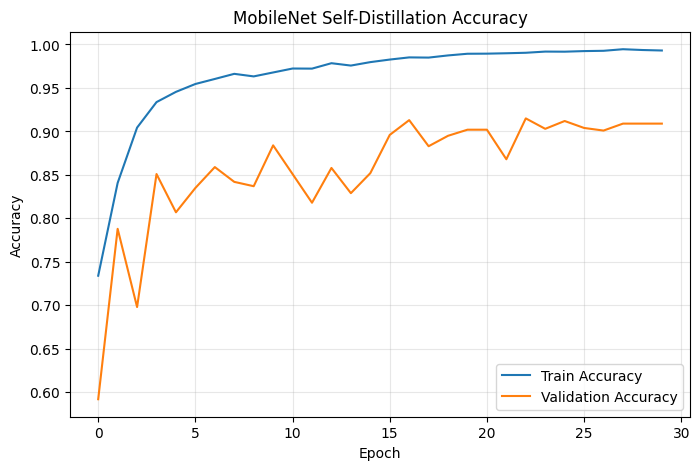

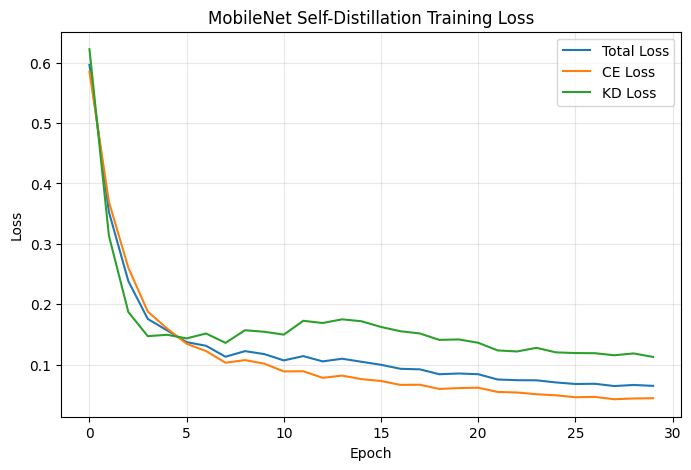

In [ ]:
# ============================================================
# TRAINING CURVES
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(history["accuracy"], label="Train Accuracy")
plt.plot(history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNet Self-Distillation Accuracy")

plt.legend()
plt.grid(alpha=0.3)

plt.show()


plt.figure(figsize=(8, 5))

plt.plot(history["loss"], label="Total Loss")
plt.plot(history["ce_loss"], label="CE Loss")
plt.plot(history["kd_loss"], label="KD Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNet Self-Distillation Training Loss")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

# **Test Prediction**

2026-09-25 17:43:22.948513: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-25 17:43:23.087100: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1790358204.369455     147 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step

2026-09-25 17:43:36.278756: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-25 17:43:36.426384: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


32/32 ━━━━━━━━━━━━━━━━━━━━ 26s 423ms/step
Test samples: 1000
              precision    recall  f1-score   support

           0     0.9140    0.7860    0.8452       500
           1     0.8123    0.9260    0.8654       500

    accuracy                         0.8560      1000
   macro avg     0.8631    0.8560    0.8553      1000
weighted avg     0.8631    0.8560    0.8553      1000



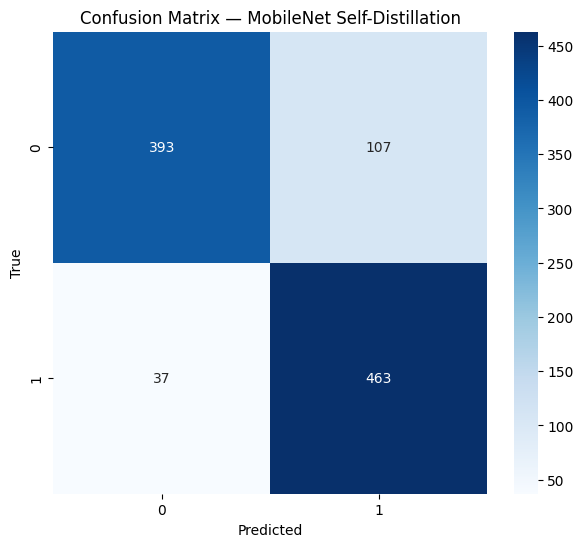

In [ ]:
# ============================================================
# TEST PREDICTION
# ============================================================

test_gen.reset()

logits = student.predict(test_gen, verbose=1)

y_prob = tf.nn.softmax(logits, axis=1).numpy()
y_pred = np.argmax(y_prob, axis=1)

y_true = test_gen.classes

print("Test samples:", len(y_true))

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

class_names = list(
    test_gen.class_indices.keys()
)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix — MobileNet Self-Distillation")

plt.show()

# **ROC-AUC**

Accuracy   : 0.8560
Precision  : 0.8123
Recall     : 0.9260
F1-score   : 0.8654
ROC-AUC    : 0.9045


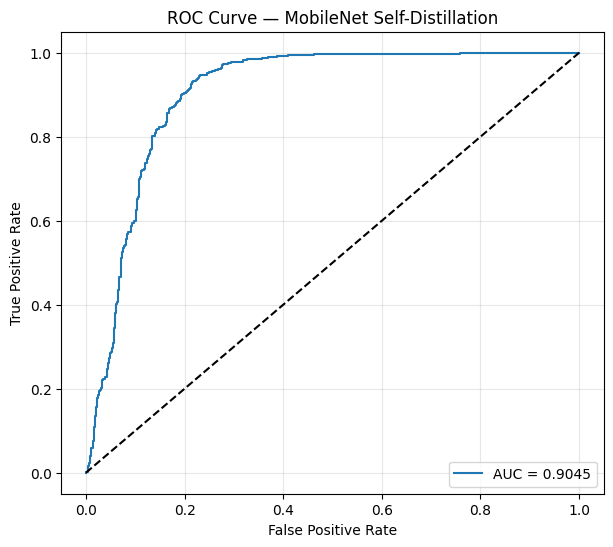

In [ ]:
# ============================================================
# MAIN TEST METRICS
# ============================================================

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="binary")
recall = recall_score(y_true, y_pred, average="binary")
f1 = f1_score(y_true, y_pred, average="binary")
auc_score = roc_auc_score(y_true, y_prob[:, 1])

print(f"Accuracy   : {accuracy:.4f}")
print(f"Precision  : {precision:.4f}")
print(f"Recall     : {recall:.4f}")
print(f"F1-score   : {f1:.4f}")
print(f"ROC-AUC    : {auc_score:.4f}")


# ============================================================
# ROC CURVE
# ============================================================

fpr, tpr, thresholds = roc_curve(y_true, y_prob[:, 1])
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — MobileNet Self-Distillation")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()

# **Model parameters**

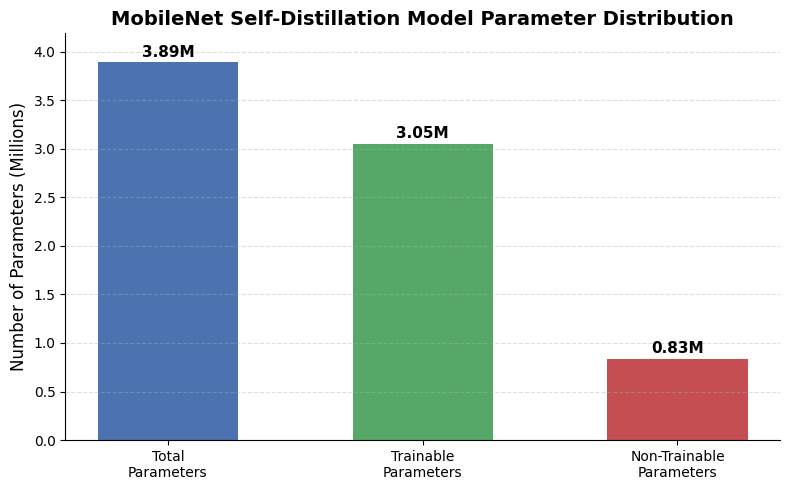

In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf

# Get parameters automatically
total_params = student.count_params()

trainable_params = sum(
    [tf.keras.backend.count_params(w) for w in student.trainable_weights]
)

non_trainable_params = sum(
    [tf.keras.backend.count_params(w) for w in student.non_trainable_weights]
)

# Convert to millions
params = [
    total_params / 1e6,
    trainable_params / 1e6,
    non_trainable_params / 1e6
]

labels = [
    "Total\nParameters",
    "Trainable\nParameters",
    "Non-Trainable\nParameters"
]

# Add colors
colors = ["#4C72B0", "#55A868", "#C44E52"]

plt.figure(figsize=(8, 5))

bars = plt.bar(labels, params, width=0.55, color=colors)

# Add values above bars
for bar, value in zip(bars, params):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.03,
        f"{value:.2f}M",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.ylabel("Number of Parameters (Millions)", fontsize=12)
plt.title("MobileNet Self-Distillation Model Parameter Distribution", fontsize=14, fontweight="bold")

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.ylim(0, max(params) + 0.3)

plt.tight_layout()
plt.show()

# **Compute Flops,Measure Inference Time,Memory Consumption**

I0000 00:00:1790358293.662557      58 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1790358293.662803      58 single_machine.cc:376] Starting new session
I0000 00:00:1790358293.678482      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790358293.680249      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.
FLOPs: 1,146,950,530
=========================Options=============================
-max_depth                  10000
-min_bytes                  0
-min_peak_bytes             0
-min_residual_bytes         0
-min_output_bytes           0
-min_micros                 0
-min_accelerator_micros     0
-min_cpu_micros             0
-min_params                 0
-min_float_ops              1
-min_occurrence             0
-step                       -1
-order_by                   float_ops
-account_type_regexes       .*
-start_name_regexes         .*
-trim_name_regexes          
-show_name_regexes          .*
-hide_name_regexes          
-account_displayed_op_only  true
-select                     float_ops
-output                     stdout:

==================Model Analysis Report======================

Doc:
op: The nod

2026-09-25 17:45:02.434959: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-25 17:45:02.569794: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Mean inference time: 96.132 ms
Std inference time: 2.588 ms
Model size: 15.147 MB
Peak GPU memory: 2724.28 MB


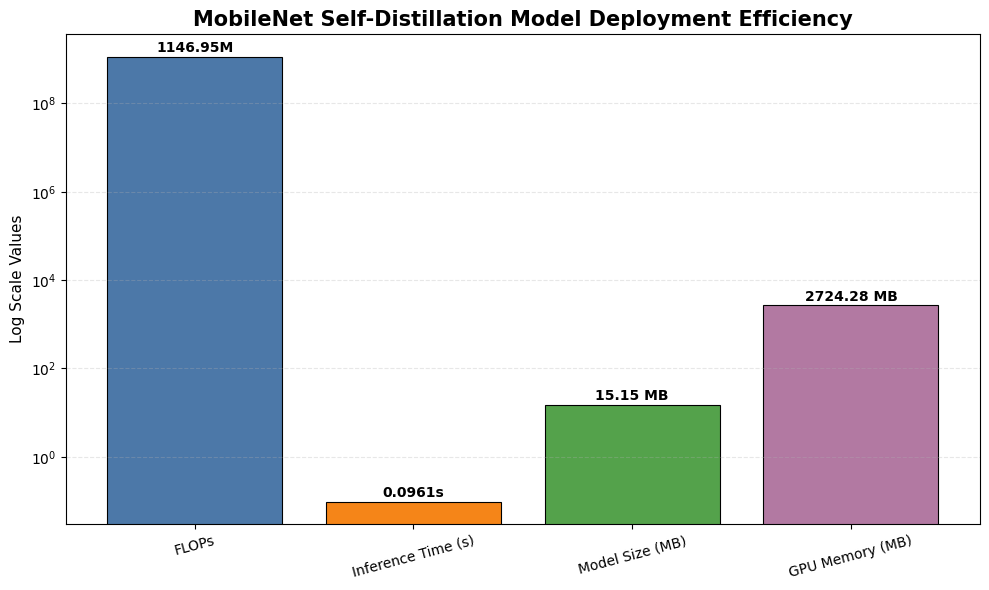

In [ ]:
import tensorflow as tf
import time
import numpy as np
import matplotlib.pyplot as plt
import os

from tensorflow.python.framework.convert_to_constants import (
    convert_variables_to_constants_v2
)


# ============================================================
# 1. FLOPs CALCULATION
# ============================================================

def get_flops(model):

    input_shape = [1, *model.input_shape[1:]]

    concrete_func = tf.function(lambda x: model(x)).get_concrete_function(
        tf.TensorSpec(input_shape, model.inputs[0].dtype)
    )

    frozen_func = convert_variables_to_constants_v2(concrete_func)
    graph_def = frozen_func.graph.as_graph_def()

    with tf.Graph().as_default() as graph:

        tf.graph_util.import_graph_def(graph_def, name="")

        run_meta = tf.compat.v1.RunMetadata()
        opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()

        flops = tf.compat.v1.profiler.profile(
            graph=graph,
            run_meta=run_meta,
            cmd="op",
            options=opts
        )

        return flops.total_float_ops


# Use STUDENT model
flops = get_flops(student)

print(f"FLOPs: {flops:,}")
print(f"FLOPs: {flops / 1e6:.2f} MFLOPs")


# ============================================================
# 2. INFERENCE TIME
# ============================================================

sample = np.random.rand(1, 224, 224, 3).astype(np.float32)

# ------------------------------------------------------------
# Warm-up
# ------------------------------------------------------------

for _ in range(10):
    student.predict(sample, verbose=0)

# ------------------------------------------------------------
# Measure inference time
# ------------------------------------------------------------

times = []

for _ in range(50):

    start = time.perf_counter()
    student.predict(sample, verbose=0)
    end = time.perf_counter()

    times.append(end - start)

mean_inference_time = np.mean(times)
std_inference_time = np.std(times)

print(f"\nMean inference time: {mean_inference_time * 1000:.3f} ms")
print(f"Std inference time: {std_inference_time * 1000:.3f} ms")


# ============================================================
# 3. MODEL SIZE
# ============================================================

model_path = "/kaggle/working/temp_student.keras"

student.save(model_path)

model_size_mb = os.path.getsize(model_path) / (1024 ** 2)

os.remove(model_path)

print(f"Model size: {model_size_mb:.3f} MB")


# ============================================================
# 4. GPU MEMORY
# ============================================================

gpu_memory_mb = 0

gpus = tf.config.list_physical_devices("GPU")

if gpus:

    try:
        details = tf.config.experimental.get_memory_info("GPU:0")
        gpu_memory_mb = details["peak"] / (1024 ** 2)

        print(f"Peak GPU memory: {gpu_memory_mb:.2f} MB")

    except Exception:
        gpu_memory_mb = 0
        print("GPU memory measurement unavailable.")


# ============================================================
# 5. PREPARE METRICS
# ============================================================

metrics = [
    "FLOPs",
    "Inference Time (s)",
    "Model Size (MB)"
]

values = [
    flops,
    mean_inference_time,
    model_size_mb
]

if gpu_memory_mb > 0:
    metrics.append("GPU Memory (MB)")
    values.append(gpu_memory_mb)


# ============================================================
# 6. COLORFUL DEPLOYMENT EFFICIENCY PLOT
# ============================================================

plt.figure(figsize=(10, 6))

bars = plt.bar(
    metrics,
    values,
    color=[
        "#4C78A8",   # Blue - FLOPs
        "#F58518",   # Orange - Inference Time
        "#54A24B",   # Green - Model Size
        "#B279A2"    # Purple - GPU Memory
    ][:len(metrics)],
    edgecolor="black",
    linewidth=0.8
)

plt.yscale("log")

plt.title("MobileNet Self-Distillation Model Deployment Efficiency", fontsize=15, fontweight="bold")
plt.ylabel("Log Scale Values", fontsize=11)

plt.xticks(rotation=15, fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.3)


# ============================================================
# VALUE ANNOTATIONS
# ============================================================

for i, bar in enumerate(bars):

    height = bar.get_height()

    if metrics[i] == "FLOPs":
        label = f"{height / 1e6:.2f}M"
    elif metrics[i] == "Inference Time (s)":
        label = f"{height:.4f}s"
    elif metrics[i] == "Model Size (MB)":
        label = f"{height:.2f} MB"
    elif metrics[i] == "GPU Memory (MB)":
        label = f"{height:.2f} MB"

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height * 1.08,
        label,
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

# **Bootstrap CI**

Bootstrap accuracy: 0.8558
95% CI: [0.8350, 0.8770]


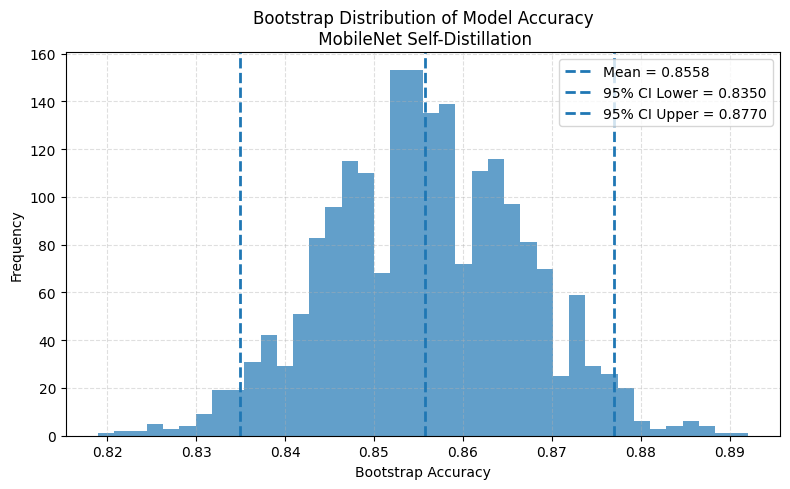

In [ ]:
# ============================================================
# BOOTSTRAP CONFIDENCE INTERVAL
# ============================================================

def bootstrap_ci(y_true, y_pred, n_iterations=2000, confidence=0.95):

    scores = []

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    n = len(y_true)

    for _ in range(n_iterations):

        indices = np.random.randint(0, n, n)
        score = accuracy_score(y_true[indices], y_pred[indices])
        scores.append(score)

    scores = np.asarray(scores)

    lower = np.percentile(scores, 2.5)
    upper = np.percentile(scores, 97.5)

    return scores, np.mean(scores), lower, upper


bootstrap_scores, mean_acc, lower, upper = bootstrap_ci(y_true, y_pred)

print(f"Bootstrap accuracy: {mean_acc:.4f}")
print(f"95% CI: [{lower:.4f}, {upper:.4f}]")


# ============================================================
# PLOT BOOTSTRAP DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

plt.hist(bootstrap_scores, bins=40, alpha=0.7)

# Mean line
plt.axvline(mean_acc, linestyle="--", linewidth=2, label=f"Mean = {mean_acc:.4f}")

# CI lines
plt.axvline(lower, linestyle="--", linewidth=2, label=f"95% CI Lower = {lower:.4f}")
plt.axvline(upper, linestyle="--", linewidth=2, label=f"95% CI Upper = {upper:.4f}")

plt.xlabel("Bootstrap Accuracy")
plt.ylabel("Frequency")
plt.title("Bootstrap Distribution of Model Accuracy\n MobileNet Self-Distillation")

plt.legend()
plt.grid(linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# **TTA**

In [ ]:
# ============================================================
# TEST-TIME AUGMENTATION
# ============================================================

import cv2
import numpy as np
import tensorflow as tf
from sklearn.metrics import accuracy_score


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

IMG_SIZE = (224, 224)
TTA_STEPS = 10
BATCH_SIZE = 32


# ============================================================
# TTA TRANSFORMATION
# ============================================================

def apply_tta(image):

    # --------------------------------------------------------
    # BGR → RGB
    # --------------------------------------------------------
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # --------------------------------------------------------
    # Resize
    # --------------------------------------------------------
    image = cv2.resize(image, IMG_SIZE)

    # --------------------------------------------------------
    # Random horizontal flip
    # --------------------------------------------------------
    if np.random.rand() > 0.5:
        image = cv2.flip(image, 1)

    # --------------------------------------------------------
    # Random brightness scaling
    # --------------------------------------------------------
    factor = 0.9 + 0.2 * np.random.rand()

    image = np.clip(
        image.astype(np.float32) * factor, 0, 255
    ).astype(np.uint8)

    return image


# ============================================================
# TTA PREDICTIONS
# ============================================================

image_paths = test_df["image_path"].tolist()

all_probs = []

for step in range(TTA_STEPS):

    print(f"TTA iteration {step + 1}/{TTA_STEPS}")

    batch_images = []

    # --------------------------------------------------------
    # Apply random augmentation to every test image
    # --------------------------------------------------------
    for path in image_paths:

        img = cv2.imread(path)

        if img is None:
            raise ValueError(f"Could not read image: {path}")

        img = apply_tta(img)
        batch_images.append(img)

    # --------------------------------------------------------
    # Convert to NumPy batch
    # --------------------------------------------------------
    batch_images = np.stack(batch_images).astype(np.float32)

    # --------------------------------------------------------
    # Model preprocessing
    # --------------------------------------------------------
    batch_images = preprocess_input(batch_images)

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------
    logits_tta = student.predict(batch_images, batch_size=BATCH_SIZE, verbose=0)

    # --------------------------------------------------------
    # Logits → probabilities
    # --------------------------------------------------------
    probs_tta = tf.nn.softmax(logits_tta, axis=1).numpy()

    all_probs.append(probs_tta)


# ============================================================
# AVERAGE TTA PREDICTIONS
# ============================================================

all_probs = np.stack(all_probs, axis=0)

y_prob_tta = np.mean(all_probs, axis=0)
y_pred_tta = np.argmax(y_prob_tta, axis=1)


# ============================================================
# TTA ACCURACY
# ============================================================

tta_accuracy = accuracy_score(y_true, y_pred_tta)


# ============================================================
# RESULTS
# ============================================================

print("\n" + "=" * 50)
print("TEST-TIME AUGMENTATION RESULTS")
print("=" * 50)

print(f"Normal accuracy : {accuracy:.4f}")
print(f"TTA accuracy    : {tta_accuracy:.4f}")
print(f"Improvement     : {tta_accuracy - accuracy:+.4f}")
print(f"TTA steps       : {TTA_STEPS}")

print("=" * 50)

TTA iteration 1/10
TTA iteration 2/10
TTA iteration 3/10
TTA iteration 4/10
TTA iteration 5/10
TTA iteration 6/10
TTA iteration 7/10
TTA iteration 8/10
TTA iteration 9/10
TTA iteration 10/10

TEST-TIME AUGMENTATION RESULTS
Normal accuracy : 0.8560
TTA accuracy    : 0.8580
Improvement     : +0.0020
TTA steps       : 10



TTA UNCERTAINTY RESULTS
Mean entropy   : 0.2060
Median entropy : 0.1360
Std entropy    : 0.2069
Min entropy    : 0.0000
Max entropy    : 0.6931


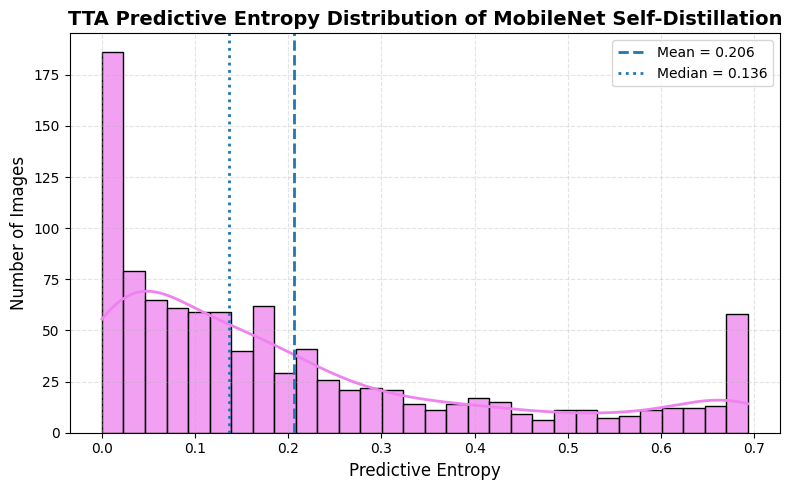

In [ ]:
# ============================================================
# TTA UNCERTAINTY — PREDICTIVE ENTROPY
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# Predictive entropy
# ------------------------------------------------------------

entropy_tta = -np.sum(y_prob_tta * np.log(y_prob_tta + 1e-8), axis=1)

# ------------------------------------------------------------
# Statistics
# ------------------------------------------------------------

mean_entropy = np.mean(entropy_tta)
median_entropy = np.median(entropy_tta)
std_entropy = np.std(entropy_tta)

print("\n" + "=" * 50)
print("TTA UNCERTAINTY RESULTS")
print("=" * 50)

print(f"Mean entropy   : {mean_entropy:.4f}")
print(f"Median entropy : {median_entropy:.4f}")
print(f"Std entropy    : {std_entropy:.4f}")
print(f"Min entropy    : {np.min(entropy_tta):.4f}")
print(f"Max entropy    : {np.max(entropy_tta):.4f}")

print("=" * 50)


# ============================================================
# PLOT — TTA PREDICTIVE ENTROPY DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

sns.histplot(
    entropy_tta,
    bins=30,
    kde=True,
    color="violet",
    alpha=0.75,
    line_kws={"linewidth": 2}
)

plt.axvline(mean_entropy, linestyle="--", linewidth=2, label=f"Mean = {mean_entropy:.3f}")
plt.axvline(median_entropy, linestyle=":", linewidth=2, label=f"Median = {median_entropy:.3f}")

plt.title("TTA Predictive Entropy Distribution of MobileNet Self-Distillation", fontsize=14, fontweight="bold")
plt.xlabel("Predictive Entropy", fontsize=12)
plt.ylabel("Number of Images", fontsize=12)

plt.grid(True, linestyle="--", alpha=0.35)
plt.legend()

plt.tight_layout()
plt.show()

# **Correct vs incorrect uncertainty**

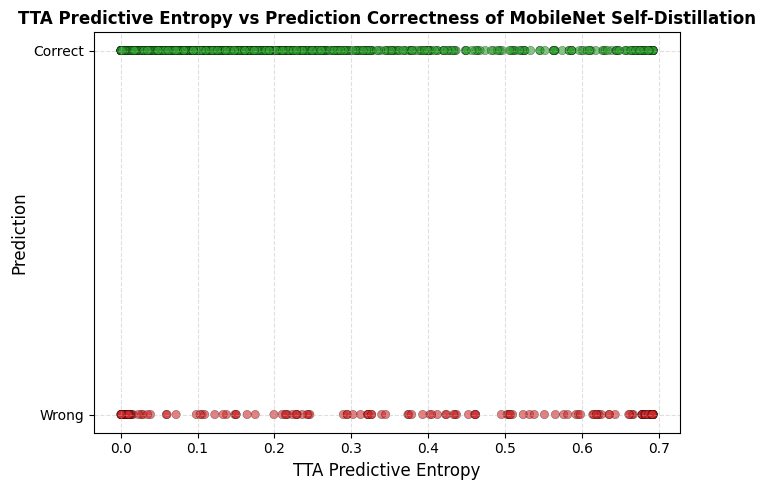

In [ ]:
# ============================================================
# TTA UNCERTAINTY vs PREDICTION CORRECTNESS
# ============================================================

correct = (y_pred_tta == y_true)

# Use TTA predictive entropy
entropy_for_plot = entropy_tta

# ------------------------------------------------------------
# Colors
# ------------------------------------------------------------

colors = np.where(
    correct,
    "#2ca02c",   # green = correct
    "#d62728"    # red = wrong
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.scatter(
    entropy_for_plot,
    correct.astype(int),
    c=colors,
    alpha=0.6,
    edgecolor="black",
    linewidth=0.3
)

plt.title(
    "TTA Predictive Entropy vs Prediction Correctness of MobileNet Self-Distillation",
    fontsize=12,
    fontweight="semibold"
)

plt.xlabel(
    "TTA Predictive Entropy",
    fontsize=12
)

plt.ylabel(
    "Prediction",
    fontsize=12
)

plt.yticks(
    [0, 1],
    ["Wrong", "Correct"]
)

plt.grid(
    axis="both",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

# **Confidence distribution**

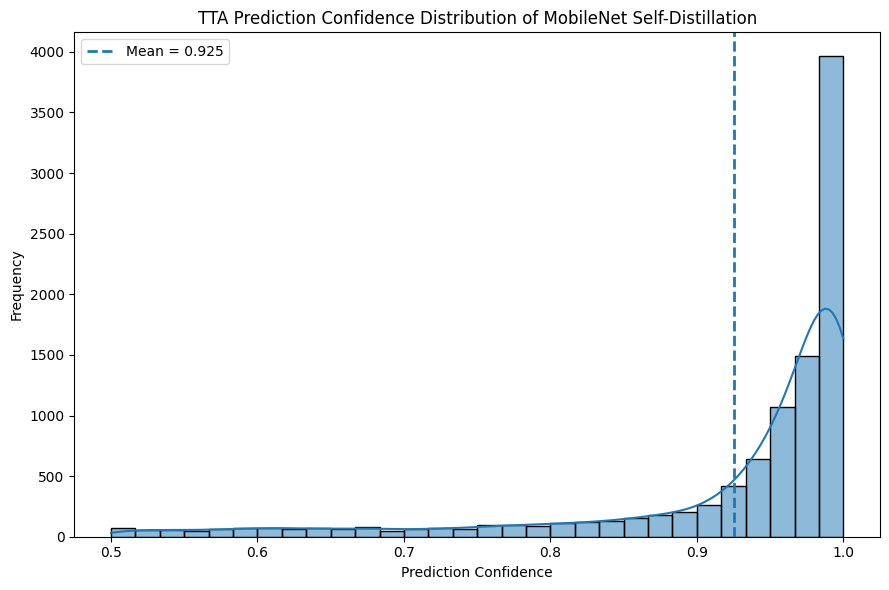

In [ ]:
# ------------------------------------------------------------
# Confidence distribution across TTA iterations
# ------------------------------------------------------------

tta_confidences = []

for step in range(TTA_STEPS):

    step_probs = all_probs[step]
    confidence = np.max(step_probs, axis=1)

    tta_confidences.extend(confidence)

tta_confidences = np.array(tta_confidences)

# ------------------------------------------------------------
# Plot confidence distribution
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

sns.histplot(tta_confidences, bins=30, kde=True)

plt.axvline(
    np.mean(tta_confidences),
    linestyle="--",
    linewidth=2,
    label=f"Mean = {np.mean(tta_confidences):.3f}"
)

plt.xlabel("Prediction Confidence")
plt.ylabel("Frequency")
plt.title("TTA Prediction Confidence Distribution of MobileNet Self-Distillation")

plt.legend()

plt.tight_layout()
plt.show()

# **ECE**

ECE: 0.0697


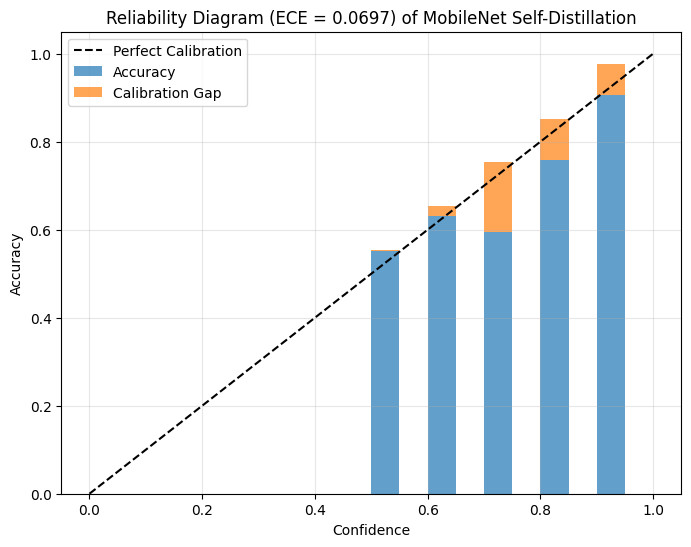

In [ ]:
# ============================================================
# EXPECTED CALIBRATION ERROR
# ============================================================

def compute_ece(probs, labels, n_bins=10):

    probs = np.asarray(probs)
    labels = np.asarray(labels)

    confidences = np.max(probs, axis=1)
    predictions = np.argmax(probs, axis=1)

    bin_edges = np.linspace(0, 1, n_bins + 1)

    ece = 0.0

    bin_acc = []
    bin_conf = []
    bin_sizes = []

    for i in range(n_bins):

        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        mask = (confidences > lower) & (confidences <= upper)
        size = np.sum(mask)

        if size > 0:

            acc = np.mean(predictions[mask] == labels[mask])
            conf = np.mean(confidences[mask])

            ece += (size / len(labels)) * abs(acc - conf)

        else:

            acc = 0
            conf = 0

        bin_acc.append(acc)
        bin_conf.append(conf)
        bin_sizes.append(size)

    return ece, bin_acc, bin_conf, bin_sizes


ece, bin_acc, bin_conf, bin_sizes = compute_ece(y_prob, y_true)

print(f"ECE: {ece:.4f}")


# ============================================================
# RELIABILITY DIAGRAM
# ============================================================

plt.figure(figsize=(8, 6))

x = np.arange(10) / 10 + 0.025

plt.bar(x, bin_acc, width=0.05, alpha=0.7, label="Accuracy")

plt.bar(
    x,
    np.array(bin_conf) - np.array(bin_acc),
    bottom=bin_acc,
    width=0.05,
    alpha=0.7,
    label="Calibration Gap"
)

plt.plot([0, 1], [0, 1], "k--", label="Perfect Calibration")

plt.xlabel("Confidence")
plt.ylabel("Accuracy")
plt.title(f"Reliability Diagram (ECE = {ece:.4f}) of MobileNet Self-Distillation")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

# **Grad Cam**

In [ ]:
# ============================================================
# FIND LAST CONVOLUTIONAL LAYER
# ============================================================

def get_last_conv_layer(model):

    for layer in reversed(model.layers):

        try:
            if len(layer.output.shape) == 4:
                return layer.name

        except:
            pass

    return None


last_conv_layer_name = get_last_conv_layer(student)

print("Last convolutional layer:", last_conv_layer_name)

Last convolutional layer: conv_pw_13_relu


In [ ]:
# ============================================================
# GRAD-CAM
# ============================================================

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, class_index):

    grad_model = Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(img_array)
        class_channel = tf.gather(predictions, class_index, axis=1)

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0)
    heatmap /= tf.reduce_max(heatmap) + 1e-8

    return heatmap.numpy()

In [ ]:
# ============================================================
# DISPLAY GRAD-CAM
# ============================================================

def display_gradcam(img_path, model, last_conv_layer_name, alpha=0.4):

    img = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
    img_array = tf.keras.utils.img_to_array(img)

    img_array_exp = np.expand_dims(img_array, axis=0)
    img_array_exp = preprocess_input(img_array_exp)

    logits = model.predict(img_array_exp, verbose=0)
    probs = tf.nn.softmax(logits, axis=1).numpy()

    pred_idx = np.argmax(probs[0])
    pred_prob = np.max(probs[0])

    heatmap = make_gradcam_heatmap(
        img_array_exp, model, last_conv_layer_name, pred_idx
    )

    heatmap_resized = cv2.resize(heatmap, IMG_SIZE)
    heatmap_uint8 = np.uint8(255 * heatmap_resized)
    heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)

    original = cv2.imread(img_path)
    original = cv2.resize(original, IMG_SIZE)

    overlay = cv2.addWeighted(original, 1 - alpha, heatmap_color, alpha, 0)

    true_label = os.path.basename(os.path.dirname(img_path))

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    plt.title(f"True: {true_label}")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title(f"Grad-CAM\nPred: {class_names[pred_idx]}")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.title(f"Confidence: {pred_prob:.3f}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


Class: malignant
Image: /kaggle/working/train/benign/200X_SOB_B_F-14-21998CD-200-033.png


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


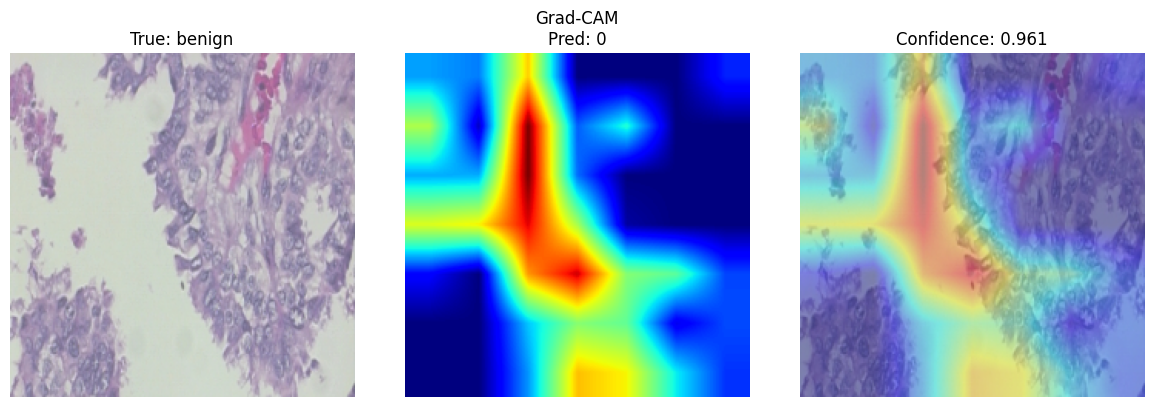


Class: benign
Image: /kaggle/working/train/malignant/100X_SOB_M_DC-14-12312-100-026.png


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


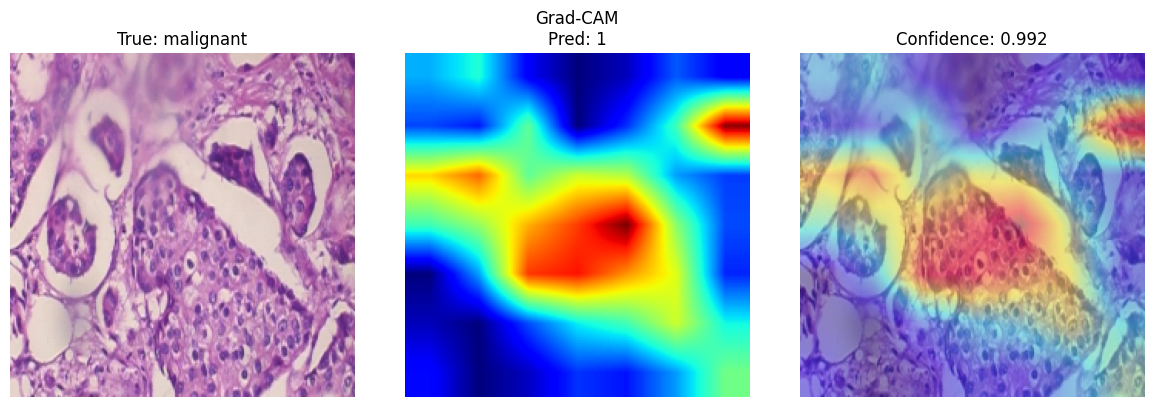

In [ ]:
# ============================================================
# GRAD-CAM EXAMPLES
# ============================================================

for cls in classes:

    # --------------------------------------------------------
    # Find numeric label corresponding to class name
    # --------------------------------------------------------
    class_idx = classes.index(cls)

    subset = test_df[test_df["label_num"].astype(int) == class_idx]

    if len(subset) == 0:
        continue

    # --------------------------------------------------------
    # Select an example
    # --------------------------------------------------------
    img_path = subset.iloc[1]["image_path"]

    print("\nClass:", cls)
    print("Image:", img_path)

    # --------------------------------------------------------
    # Generate Grad-CAM
    # --------------------------------------------------------
    display_gradcam(img_path, student, last_conv_layer_name)


Class: malignant
Image: /kaggle/working/train/benign/400X_SOB_B_F-14-25197-400-061.png


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


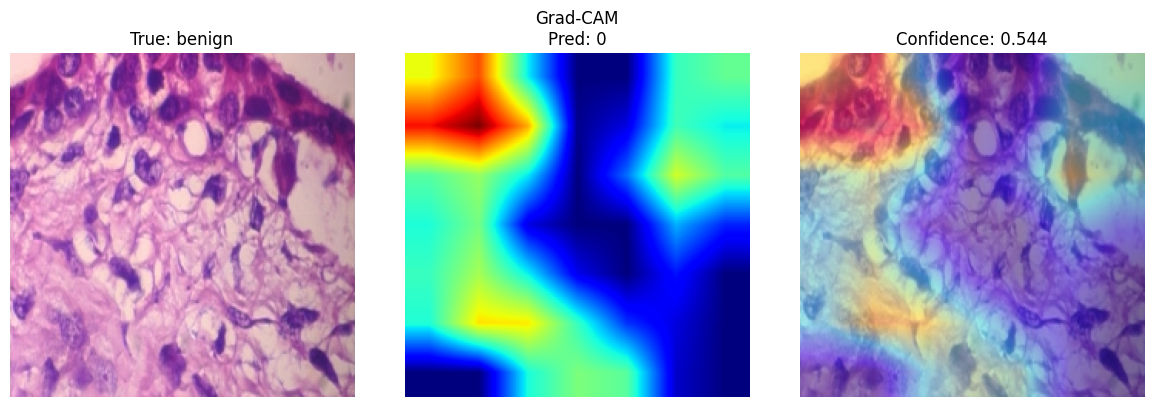


Class: benign
Image: /kaggle/working/train/malignant/40X_SOB_M_DC-14-15696-40-013.png


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


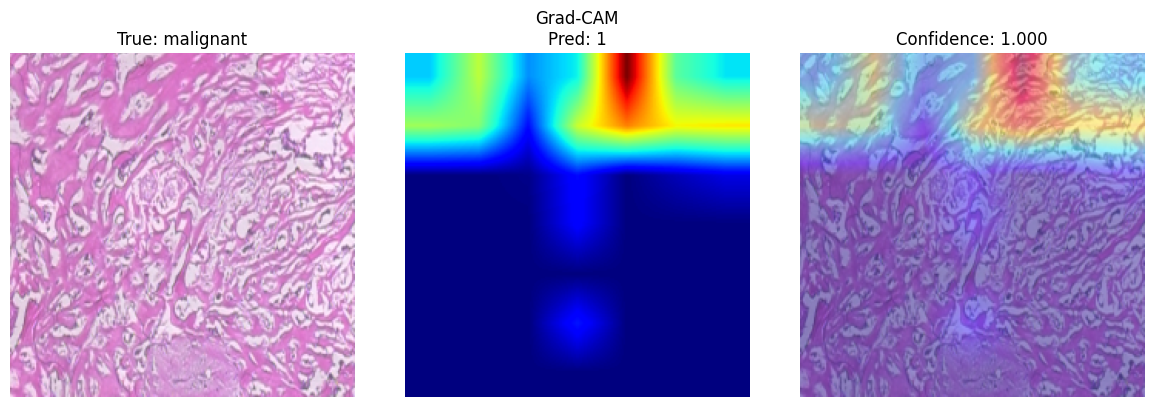

In [ ]:
# ============================================================
# GRAD-CAM EXAMPLES
# ============================================================

for cls in classes:

    # --------------------------------------------------------
    # Find numeric label corresponding to class name
    # --------------------------------------------------------
    class_idx = classes.index(cls)

    subset = test_df[test_df["label_num"].astype(int) == class_idx]

    if len(subset) == 0:
        continue

    # --------------------------------------------------------
    # Select an example
    # --------------------------------------------------------
    img_path = subset.iloc[2]["image_path"]

    print("\nClass:", cls)
    print("Image:", img_path)

    # --------------------------------------------------------
    # Generate Grad-CAM
    # --------------------------------------------------------
    display_gradcam(img_path, student, last_conv_layer_name)


Class: malignant
Image: /kaggle/working/train/benign/200X_SOB_B_F-14-14134E-200-001.png


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


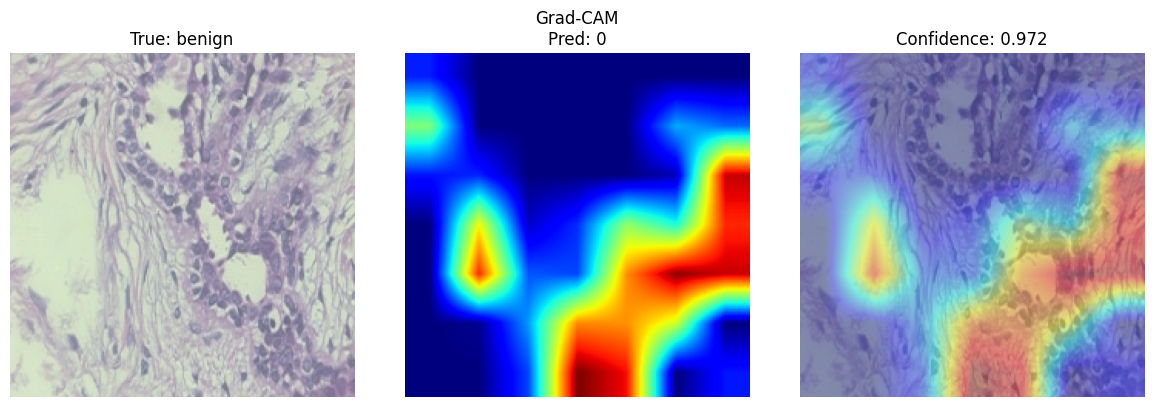


Class: benign
Image: /kaggle/working/train/malignant/40X_SOB_M_DC-14-14946-40-018.png


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


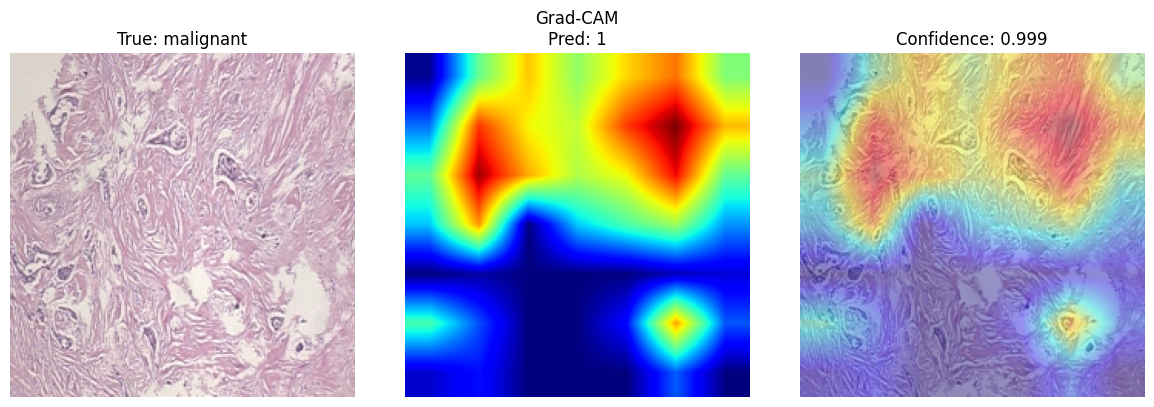

In [ ]:
# ============================================================
# GRAD-CAM EXAMPLES
# ============================================================

for cls in classes:

    # --------------------------------------------------------
    # Find numeric label corresponding to class name
    # --------------------------------------------------------
    class_idx = classes.index(cls)

    subset = test_df[test_df["label_num"].astype(int) == class_idx]

    if len(subset) == 0:
        continue

    # --------------------------------------------------------
    # Select an example
    # --------------------------------------------------------
    img_path = subset.iloc[3]["image_path"]

    print("\nClass:", cls)
    print("Image:", img_path)

    # --------------------------------------------------------
    # Generate Grad-CAM
    # --------------------------------------------------------
    display_gradcam(img_path, student, last_conv_layer_name)